**LIKE REPORT by Kevin Ku**


 **1. Who or what is the source of your personal Instagram data? (you downloaded the data, but did you create it?):** My source for my personal Instagram account data is Instagram. 

 **2. Why was this data created and what purposes can the data serve?:** The data is created when I like people's post and instagram keep track of it. The purpose of the data serve is to understand how people use instagram to support features 

**3.In what ways may this data be reliable?:** The data can be realiable if they are broadcast events

**4. In what ways may this data be unreliable?:** When I accidentally like a post.

## Instagram likes Data

I am opening my liked_json file


In [159]:
    import json

    import pandas as pd

    with open('liked_posts.json','r') as f:
         data=json.load(f)

        
    data[0]
    

{'timestamp': 1789499204,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/p/DdUZYELFBgg/',
   'href': 'https://www.instagram.com/p/DdUZYELFBgg/'},
  {'label': 'Caption',
   'value': 'Ryan Day said that the young guys on both sides of the ball are going to play more moving forwards. \n-\nKhary Wilder was one of the names that Day listed as needing more snaps throughout this season. \n-\n#GoBucks'},
  {'label': 'Title', 'value': ''},
  {'dict': [{'dict': [{'label': 'Name', 'value': 'gobucks'}], 'title': ''}],
   'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL', 'value': ''},
      {'label': 'Name', 'value': 'Ohio State Buckeyes'},
      {'label': 'Username', 'value': 'buckeye.landing'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': '17907302511551754'}

In [113]:
row={}
row['timestamp']=data[0]['timestamp']

row



{'timestamp': 1789499204}

This creates emmpty dictionary called row. The instagram data is store underneath the name timestamp.

In [114]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']]=item['value']


row 

{'timestamp': 1789499204,
 'URL': 'https://www.instagram.com/p/DdUZYELFBgg/',
 'Caption': 'Ryan Day said that the young guys on both sides of the ball are going to play more moving forwards. \n-\nKhary Wilder was one of the names that Day listed as needing more snaps throughout this season. \n-\n#GoBucks',
 'Title': ''}

In [115]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['Owner ' + owner_item['label']] = owner_item['value']

row

{'timestamp': 1789499204,
 'URL': 'https://www.instagram.com/p/DdUZYELFBgg/',
 'Caption': 'Ryan Day said that the young guys on both sides of the ball are going to play more moving forwards. \n-\nKhary Wilder was one of the names that Day listed as needing more snaps throughout this season. \n-\n#GoBucks',
 'Title': '',
 'Owner URL': '',
 'Owner Name': 'Ohio State Buckeyes',
 'Owner Username': 'buckeye.landing'}

In [116]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']
    
    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)

tidy_rows[:2]

[{'timestamp': 1789499204,
  'URL': 'https://www.instagram.com/p/DdUZYELFBgg/',
  'Caption': 'Ryan Day said that the young guys on both sides of the ball are going to play more moving forwards. \n-\nKhary Wilder was one of the names that Day listed as needing more snaps throughout this season. \n-\n#GoBucks',
  'Title': '',
  'Owner URL': '',
  'Owner Name': 'Ohio State Buckeyes',
  'Owner Username': 'buckeye.landing'},
 {'timestamp': 1789436284,
  'URL': 'https://www.instagram.com/p/DdR6bRnnwel/',
  'Caption': 'They Kent read, Kent write, and definitely Kent win.\n\n#ohiostate #buckeyes #columbus',
  'Title': '',
  'Owner URL': 'https://lvcollective.tripleseat.com/party_request/46333',
  'Owner Name': 'OHIO STATE SPORTS BAR',
  'Owner Username': 'victorylapcolumbus'}]

In [117]:
likes_df=pd.DataFrame(tidy_rows)
likes_df.head(10)

,timestamp,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,1789499204,https://www.instagram.com/p/DdUZYELFBgg/,Ryan Day said that the young guys on both side...,,,Ohio State Buckeyes,buckeye.landing
1,1789436284,https://www.instagram.com/p/DdR6bRnnwel/,"They Kent read, Kent write, and definitely Ken...",,https://lvcollective.tripleseat.com/party_requ...,OHIO STATE SPORTS BAR,victorylapcolumbus
2,1789435954,https://www.instagram.com/reel/DdShLz_x_0a/,Printing & location freedom >>>,,https://youtube.com/@thejackandrewss?si=3Z8jRR...,Jack Andrews,thejackandrews
3,1789412239,https://www.instagram.com/p/DdRxI1nxfQe/,Time is set for Illinois â°,,https://linktr.ee/OhioStateFootball,Ohio State Football,ohiostatefb
4,1789403511,https://www.instagram.com/reel/DdRiC5RCbE4/,"""Oooh that one's really spicy...I'm ready for ...",,https://linktr.ee/h2oathens,H2O Church Athens,h2oathens
5,1789401389,https://www.instagram.com/p/DdRfEWXEdex/,GAMEWEEK. BEAT KENT STATE. \n-\nBOUNCE BACK. \...,,,Ohio State Buckeyes,buckeye.landing
6,1789396936,https://www.instagram.com/p/DdRXYZduOky/,MUSIC MONDAY ð¥\n\n#christianmusic #ohiostat...,,https://docs.google.com/document/u/0/d/1XG1FB8...,,the.courageousathlete
7,1789395098,https://www.instagram.com/p/DdRRkmgs-Nr/,Back in the âShoe ð,,https://linktr.ee/OhioStateFootball,Ohio State Football,ohiostatefb
8,1789352330,https://www.instagram.com/reel/DdPnUNiOAWq/,Wrestling D1 athlete for gas,,https://www.youtube.com/@ADfitnesss,AD fitness,a.dfitnessss
9,1789352177,https://www.instagram.com/reel/DdP_KgQRDTb/,Best feeling hands downâ¦,,https://youtube.com/@thejackandrewss?si=3Z8jRR...,Jack Andrews,thejackandrews


In [ ]:
This data frame keeps track of post I like.

In [118]:
likes_df['DateTime'] = pd.to_datetime(likes_df['timestamp'], unit='s')
likes_df[['timestamp', 'DateTime']].head()

,timestamp,DateTime
0,1789499204,2026-09-15 19:06:44
1,1789436284,2026-09-15 01:38:04
2,1789435954,2026-09-15 01:32:34
3,1789412239,2026-09-14 18:57:19
4,1789403511,2026-09-14 16:31:51


In [119]:
likes_df.head(10)

,timestamp,URL,Caption,Title,Owner URL,Owner Name,Owner Username,DateTime
0,1789499204,https://www.instagram.com/p/DdUZYELFBgg/,Ryan Day said that the young guys on both side...,,,Ohio State Buckeyes,buckeye.landing,2026-09-15 19:06:44
1,1789436284,https://www.instagram.com/p/DdR6bRnnwel/,"They Kent read, Kent write, and definitely Ken...",,https://lvcollective.tripleseat.com/party_requ...,OHIO STATE SPORTS BAR,victorylapcolumbus,2026-09-15 01:38:04
2,1789435954,https://www.instagram.com/reel/DdShLz_x_0a/,Printing & location freedom >>>,,https://youtube.com/@thejackandrewss?si=3Z8jRR...,Jack Andrews,thejackandrews,2026-09-15 01:32:34
3,1789412239,https://www.instagram.com/p/DdRxI1nxfQe/,Time is set for Illinois â°,,https://linktr.ee/OhioStateFootball,Ohio State Football,ohiostatefb,2026-09-14 18:57:19
4,1789403511,https://www.instagram.com/reel/DdRiC5RCbE4/,"""Oooh that one's really spicy...I'm ready for ...",,https://linktr.ee/h2oathens,H2O Church Athens,h2oathens,2026-09-14 16:31:51
5,1789401389,https://www.instagram.com/p/DdRfEWXEdex/,GAMEWEEK. BEAT KENT STATE. \n-\nBOUNCE BACK. \...,,,Ohio State Buckeyes,buckeye.landing,2026-09-14 15:56:29
6,1789396936,https://www.instagram.com/p/DdRXYZduOky/,MUSIC MONDAY ð¥\n\n#christianmusic #ohiostat...,,https://docs.google.com/document/u/0/d/1XG1FB8...,,the.courageousathlete,2026-09-14 14:42:16
7,1789395098,https://www.instagram.com/p/DdRRkmgs-Nr/,Back in the âShoe ð,,https://linktr.ee/OhioStateFootball,Ohio State Football,ohiostatefb,2026-09-14 14:11:38
8,1789352330,https://www.instagram.com/reel/DdPnUNiOAWq/,Wrestling D1 athlete for gas,,https://www.youtube.com/@ADfitnesss,AD fitness,a.dfitnessss,2026-09-14 02:18:50
9,1789352177,https://www.instagram.com/reel/DdP_KgQRDTb/,Best feeling hands downâ¦,,https://youtube.com/@thejackandrewss?si=3Z8jRR...,Jack Andrews,thejackandrews,2026-09-14 02:16:17


In [120]:
likes_df.shape

(2632, 8)

In [121]:
likes_df['Owner Username'].isna().sum()

np.int64(0)

In [122]:
likes_df.dtypes

timestamp                 int64
URL                         str
Caption                     str
Title                       str
Owner URL                   str
Owner Name                  str
Owner Username              str
DateTime          datetime64[s]
dtype: object

In [123]:
likes_df.groupby("Owner Username")["DateTime"].count()

Owner Username
247sports          4
305sportss         1
314graphics_       1
35_moss            1
918graphics        1
                  ..
yay.0608           1
yea.j2             1
yusufm1300         3
zach_hartman24    36
zachbeckman8       2
Name: DateTime, Length: 416, dtype: int64

In [124]:
likes_by_account = (
    likes_df.groupby("Owner Username")["DateTime"]
    .count()
    .sort_values(ascending=False)
)
likes_by_account.head(10)


Owner Username
ohiostatefb              254
h2ocincinnati            135
h2ochurchkent            130
h2oathens                101
a.dfitnessss              90
realzefley                74
buckeye.landing           54
h2o_qwest                 46
ohiostathletics           45
the.courageousathlete     44
Name: DateTime, dtype: int64

This is a list of account that I frequently like the most.

**Comment section**



**Hypothesis**

I like more post more than commenting on post.


**Theoretical element**

I think this happen because liking post is more easier than writing comments. 


**Statistical element**

I can test my hypothesis by counting how post I liked and comparing with how many post I comment.  





In [157]:
    import json

    import pandas as pd

    with open('post_comments.json','r') as f:
         data=json.load(f)

        
    data[0]
    

{'media_list_data': [{'uri': ''}],
 'string_map_data': {'Comment': {'value': '@h2ochurchkent vs @h2oysu'},
  'Media Owner': {'value': 'h2ochurchkent'},
  'Time': {'timestamp': 1788959194}}}

In [126]:
row={}
row['timestamp']=data[0]['string_map_data']['Time']['timestamp']

row

{'timestamp': 1788959194}

In [127]:
for label, item in data[0]['string_map_data'].items():
    if 'value' in item:
        row[label]= item['value']
    elif 'timestamp' in item:
        row[label]= item['timestamp']


row 

{'timestamp': 1788959194,
 'Comment': '@h2ochurchkent vs @h2oysu',
 'Media Owner': 'h2ochurchkent',
 'Time': 1788959194}

In [128]:

row={}

for label, item in data[0]['string_map_data'].items():
    if 'value' in item:
        row[label] = item['value']
    elif 'timestamp' in item:
        row[label] = item['timestamp']

row

{'Comment': '@h2ochurchkent vs @h2oysu',
 'Media Owner': 'h2ochurchkent',
 'Time': 1788959194}

In [146]:
tidy_rows = []

for entry in data:
    row = {}
    
    
    for label, item in entry['string_map_data'].items():
        if 'value' in item:
            row[label] = item['value']
        elif 'timestamp' in item:
           
            row[label] = item['timestamp']
    tidy_rows.append(row)

tidy_rows[:2]

[{'Comment': '@h2ochurchkent vs @h2oysu',
  'Media Owner': 'h2ochurchkent',
  'Time': 1788959194},
 {'Comment': 'Like that cross â\x9c\x9dï¸\x8f',
  'Media Owner': 'hash7563',
  'Time': 1788383868}]

In [147]:
comments_df=pd.DataFrame(tidy_rows)
comments_df.head(10)

,Comment,Media Owner,Time
0,@h2ochurchkent vs @h2oysu,h2ochurchkent,1788959194
1,Like that cross âï¸,hash7563,1788383868
2,Cincy vibez,halliegiffin,1788037176
3,Tier 1 College Church organization group âï¸...,h2ochurchkent,1787889279
4,Look at that roster ðª,h2ochurchkent,1787788984
5,Good Jobð,maxmoloney13,1787777951
6,Good job Nick ð,nick_lawrensen,1786900844
7,ETHAN WENDT!!!!!,e.wendt33,1784249205
8,Looks drippy,benehrxsman,1783953189
9,ð¥,benehrxsman,1783479361


## Total Likes

In [172]:
total_likes = len(likes_df)

total_likes

2632

## Comment DataFrame Description

The data represents the list comment from recent to past

I think the DataFrame is tidy because each row represent one instagram comment.

I can use this to test my hypothesis because I can count how many comments I made.



In [160]:
comments_df['DateTime'] = pd.to_datetime(comments_df['Time'], unit='s')

comments_df[['Time', 'DateTime']].head()

,Time,DateTime
0,1788959194,2026-09-09 13:06:34
1,1788383868,2026-09-02 21:17:48
2,1788037176,2026-08-29 20:59:36
3,1787889279,2026-08-28 03:54:39
4,1787788984,2026-08-27 00:03:04


In [161]:
comments_df.head(10)

,Comment,Media Owner,Time,DateTime
0,@h2ochurchkent vs @h2oysu,h2ochurchkent,1788959194,2026-09-09 13:06:34
1,Like that cross âï¸,hash7563,1788383868,2026-09-02 21:17:48
2,Cincy vibez,halliegiffin,1788037176,2026-08-29 20:59:36
3,Tier 1 College Church organization group âï¸...,h2ochurchkent,1787889279,2026-08-28 03:54:39
4,Look at that roster ðª,h2ochurchkent,1787788984,2026-08-27 00:03:04
5,Good Jobð,maxmoloney13,1787777951,2026-08-26 20:59:11
6,Good job Nick ð,nick_lawrensen,1786900844,2026-08-16 17:20:44
7,ETHAN WENDT!!!!!,e.wendt33,1784249205,2026-07-17 00:46:45
8,Looks drippy,benehrxsman,1783953189,2026-07-13 14:33:09
9,ð¥,benehrxsman,1783479361,2026-07-08 02:56:01


In [162]:
likes_df.shape

(2632, 8)

In [163]:
comments_df['Time'].isna().sum()



np.int64(0)

In [164]:
comments_df.dtypes

Comment                  str
Media Owner              str
Time                   int64
DateTime       datetime64[s]
dtype: object

In [165]:
comments_df.groupby("Media Owner")["DateTime"].count()

Media Owner
_haychen             1
aiden_donachy28      1
aidenyoo             1
ali_bahar32          1
b_dubs52             1
benehrxsman          3
charlie_mitchell5    1
e.wendt33            2
h2o_qwest            1
h2oathens            1
h2ochurchkent        3
h2ocincinnati        1
halliegiffin         5
hash7563             3
itsnot.anwar         1
jack_lindberg34      1
kevinn.kuu           2
maxmoloney13         3
moloney.sam          1
nick_lawrensen       2
realzefley           1
taylor.hawkinsss     1
thejackandrews       1
zachbeckman8         1
Name: DateTime, dtype: int64

In [166]:
comments_by_account = (
    comments_df.groupby("Media Owner")["DateTime"]
    .count()
    .sort_values(ascending=False)
)
comments_by_account.head(10)

Media Owner
halliegiffin         5
benehrxsman          3
h2ochurchkent        3
hash7563             3
maxmoloney13         3
e.wendt33            2
nick_lawrensen       2
kevinn.kuu           2
charlie_mitchell5    1
b_dubs52             1
Name: DateTime, dtype: int64

These are the list of account that I frequent comment.

## Total comment

In [174]:
total_comments = len(comments_df)

total_comments

40

## Results

I liked 2632 of my post and I comment 40 post

In [175]:
comparison_df = pd.DataFrame({
    "Activity": ["Likes", "Comments"],
    "Count": [total_likes, total_comments]
})

comparison_df

,Activity,Count
0,Likes,2632
1,Comments,40


<Axes: title={'center': 'Total Instagram Likes vs. Comments'}, xlabel='Activity'>

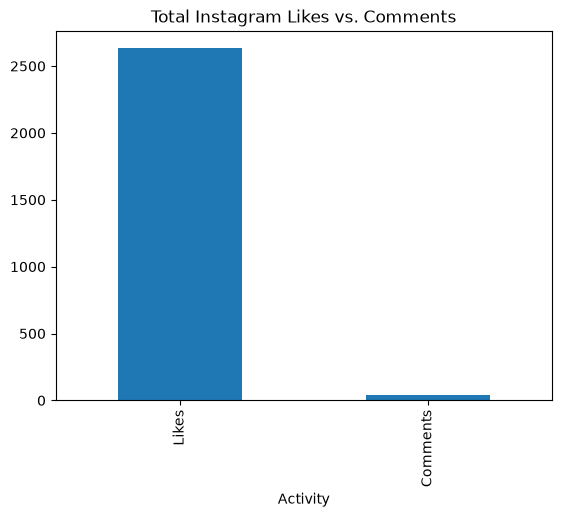

In [177]:
comparison_df.plot(
    x="Activity",
    y="Count",
    kind="bar",
    legend=False,
    title="Total Instagram Likes vs. Comments"
)